# **Теория №5. Основные методы OpenCV (Часть №4). Обнаружение границ и контуров. Афинные преобразования**

## Выделение границ и контуров в компьютерном зрении

Выделение границ и контуров является одним из ключевых этапов в обработке изображений и компьютерном зрении. Границы и контуры позволяют выделять объекты на изображении, определять их форму, размеры и положение. Далее мы рассмотрим теорию и математическое обоснование операторов Собеля, Лапласа и Кэнни, а также методы обнаружения контуров с практическими примерами кода на Python с использованием библиотеки OpenCV.

## 1. Операторы для выделения границ

### 1.1. Оператор Собеля

**Оператор Собеля** — это инструмент в обработке изображений, который помогает выявлять границы объектов на изображении. Он делает это, вычисляя изменения яркости между соседними пикселями, что позволяет определить, где находятся границы объектов.





##### Основные концепции

1. **Градиент изображения**:
   - Градиент показывает, насколько быстро изменяется яркость изображения в определённой точке. Если градиент велик, это указывает на резкое изменение яркости, что часто соответствует границе объекта.

2. **Свёртка**:
   - Свёртка — это математическая операция, которая применяется к изображению с использованием специального фильтра (ядра). В случае оператора Собеля используются два разных ядра для выявления изменений в горизонтальном и вертикальном направлениях.

##### Ядра Собеля

- Горизонтальное ядро (выявляет вертикальные границы):

  $
  G_x = \begin{bmatrix}
  -1 & 0 & +1 \\
  -2 & 0 & +2 \\
  -1 & 0 & +1 \\
  \end{bmatrix}
  $

- Вертикальное ядро (выявляет горизонтальные границы):

  $
  G_y = \begin{bmatrix}
  -1 & -2 & -1 \\
   0 &  0 &  0 \\
  +1 & +2 & +1 \\
  \end{bmatrix}
  $

##### Процесс вычисления

1. **Применение свёртки**:
   - Изображение свёртывается с каждым из ядер. Это означает, что каждое ядро проходит по изображению и вычисляет новое значение для каждого пикселя, основываясь на значениях соседних пикселей.
   - Результатом являются два новых изображения: одно с горизонтальными градиентами $G_x$, другое с вертикальными ($G_y$.

2. **Вычисление градиента**:
   - После получения $G_x$ и $G_y$, общий градиент в каждой точке изображения можно вычислить как:
$
G = \sqrt{G_x^2 + G_y^2}
$

   - На практике часто используют упрощённую версию без квадратного корня для ускорения вычислений, так как это всё равно даёт хорошее приближение для выявления границ.

#### Реализация в OpenCV



Функция `cv2.Sobel` используется для выполнения операции Собеля, которая позволяет находить границы в изображении путём вычисления градиента интенсивности изображения. Это полезно для выделения областей с резкими изменениями яркости, что часто соответствует границам объектов.



#### Синтаксис

```python
cv2.Sobel(src, ddepth, dx, dy, dst=None, ksize=3, scale=1, delta=0, borderType=cv2.BORDER_DEFAULT)
```

#### Параметры

1. **`src`**:
   - **Тип**: `numpy.ndarray`
   - **Описание**: Исходное изображение, к которому применяется оператор Собеля. Должно быть одноканальным (градации серого).

2. **`ddepth`**:
   - **Тип**: `int`
   - **Описание**: Желаемая глубина конечного изображения. Обычно используются значения: `cv2.CV_8U`, `cv2.CV_16U`, `cv2.CV_16S`, `cv2.CV_32F`, и `cv2.CV_64F`. Этот параметр определяет точность выходного изображения.

3. **`dx`**:
   - **Тип**: `int`
   - **Описание**: Порядок производной по x. Например, `dx=1` означает первую производную по x.

4. **`dy`**:
   - **Тип**: `int`
   - **Описание**: Порядок производной по y. Например, `dy=1` означает первую производную по y.

5. **`dst`**:
   - **Тип**: `numpy.ndarray` (необязательный)
   - **Описание**: Конечное изображение того же размера и типа, что и `src`. Если не указано, создается автоматически.

6. **`ksize`**:
   - **Тип**: `int`
   - **Описание**: Размер расширенного ядра Собеля; должен быть 1, 3, 5 или 7. По умолчанию 3. Больше размеры могут захватывать больше деталей, но также могут вводить больше шума.

7. **`scale`**:
   - **Тип**: `float`
   - **Описание**: Необязательный коэффициент масштабирования для вычисленных значений производной. По умолчанию установлен в 1.

8. **`delta`**:
   - **Тип**: `float`
   - **Описание**: Необязательное значение, добавляемое к результатам до их сохранения в `dst`. Это может использоваться для корректировки яркости выходного изображения.

9. **`borderType`**:
   - **Тип**: `int`
   - **Описание**: Метод экстраполяции пикселей. Этот параметр определяет, как обрабатываются границы изображения. Обычные варианты включают `cv2.BORDER_CONSTANT`, `cv2.BORDER_REFLECT`, и `cv2.BORDER_REPLICATE`.

**Практическое применение с кодом**

In [ ]:
!curl -o image.jpg https://2spalnika.ru/wp-content/uploads/2022/12/zhivotniy-mir-hibin-800x600.jpg

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  103k  100  103k    0     0  52622      0  0:00:02  0:00:02 --:--:-- 52649


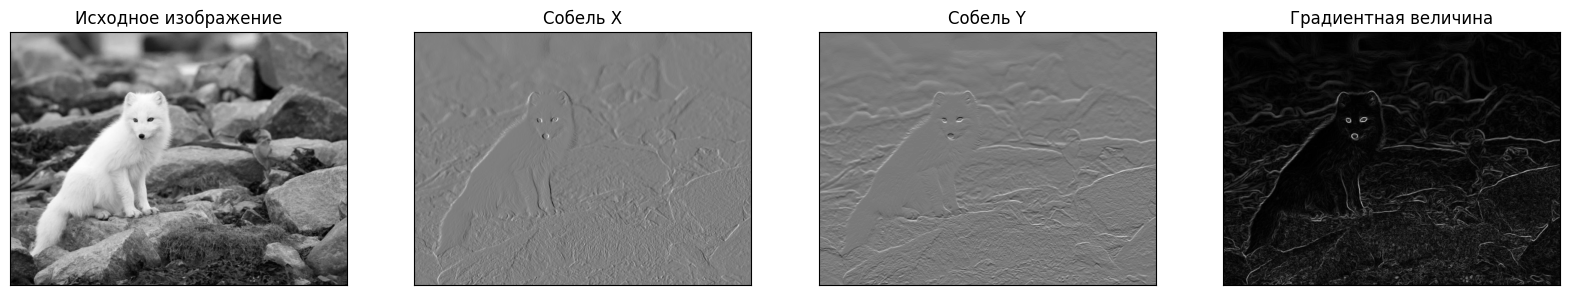

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загрузим изображение в градациях серого
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)

# Вычислим производные по X и Y
sobelx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)  # Производная по X
sobely = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)  # Производная по Y

# Вычислим градиентную величину
sobel = cv2.magnitude(sobelx, sobely)

# Увеличим размер графиков
plt.figure(figsize=(20, 5))

# Отобразим результаты
plt.subplot(1, 4, 1), plt.imshow(img, cmap='gray')
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(1, 4, 2), plt.imshow(sobelx, cmap='gray')
plt.title('Собель X'), plt.xticks([]), plt.yticks([])
plt.subplot(1, 4, 3), plt.imshow(sobely, cmap='gray')
plt.title('Собель Y'), plt.xticks([]), plt.yticks([])
plt.subplot(1, 4, 4), plt.imshow(sobel, cmap='gray')
plt.title('Градиентная величина'), plt.xticks([]), plt.yticks([])

plt.show()

### 1.2. Оператор Лапласа

**Оператор Лапласа** — это математический инструмент, используемый в обработке изображений для обнаружения границ. Он основан на вычислении вторых производных изображения, что позволяет выявлять области, где интенсивность пикселей изменяется резко. Это делает его полезным для обнаружения контуров и границ объектов на изображении.

#### Как это работает?



Разберём, как работает оператор Лапласа для обнаружения границ на изображении, шаг за шагом:

##### Шаг 1: Понимание вторых производных

- **Вторые производные**: В математике вторая производная функции показывает, как изменяется скорость изменения функции. В контексте изображений это означает, что мы ищем места, где интенсивность пикселей изменяется с ускорением. Такие изменения часто указывают на границы объектов.

##### Шаг 2: Выбор ядра Лапласа

- **Ядра Лапласа**: Для вычисления вторых производных изображения используются специальные матрицы, называемые ядрами. Наиболее распространённые ядра Лапласа выглядят так:

  - Ядро 3x3 для выявления изменений в четырёх направлениях:
        
  $
  K = \begin{bmatrix}
  0 & 1 & 0 \\
  1 & -4 & 1 \\
  0 & 1 & 0 \\
  \end{bmatrix}
  $

  - Ядро 3x3 для выявления изменений во всех восьми направлениях:
        
  $
  K = \begin{bmatrix}
  1 & 1 & 1 \\
  1 & -8 & 1 \\
  1 & 1 & 1 \\
  \end{bmatrix}
  $

  Эти ядра помогают выявлять изменения интенсивности в разных направлениях, что позволяет обнаруживать границы.

##### Шаг 3: Применение свёртки

- **Свёртка**: Это процесс, при котором ядро проходит по изображению и вычисляет новое значение для каждого пикселя, основываясь на значениях соседних пикселей. Это позволяет выявлять изменения интенсивности в изображении.

  - Для каждого пикселя в изображении ядро накладывается на область вокруг этого пикселя.
  - Значения пикселей умножаются на соответствующие значения ядра.
  - Результаты суммируются, и это значение становится новым значением пикселя в выходном изображении.

##### Шаг 4: Обработка результата

- **Обработка изображения**: После применения свёртки с ядром Лапласа, результатом будет изображение, где границы объектов выделены. Это изображение может содержать как положительные, так и отрицательные значения, поэтому часто применяется преобразование для отображения результата в видимом диапазоне.



#### Реализация в OpenCV

Функция `cv2.Laplacian` в OpenCV используется для вычисления второго производного изображения, что позволяет выявлять границы и контуры объектов. Давайте рассмотрим её параметры и работу более подробно.

#### Синтаксис функции

```python
cv2.Laplacian(src, ddepth, dst=None, ksize=1, scale=1, delta=0, borderType=cv2.BORDER_DEFAULT)
```

#### Параметры

1. **`src`**:
   - **Тип**: `numpy.ndarray`
   - **Описание**: Исходное изображение, к которому применяется оператор Лапласа. Обычно это изображение в градациях серого, но может быть и цветным.

2. **`ddepth`**:
   - **Тип**: `int`
   - **Описание**: Желаемая глубина конечного изображения. Это определяет, в каком формате будут храниться результаты вычислений. Обычно используются значения `cv2.CV_16S`, `cv2.CV_32F`, и `cv2.CV_64F`, чтобы избежать переполнения при вычислениях.

3. **`dst`**:
   - **Тип**: `numpy.ndarray` (необязательный)
   - **Описание**: Конечное изображение того же размера и типа, что и `src`. Если не указано, создается автоматически.

4. **`ksize`**:
   - **Тип**: `int`
   - **Описание**: Размер ядра Лапласа. Обычно используется значение 1, что соответствует стандартному ядру. Большие значения могут использоваться для более сглаженного результата, но это редко необходимо.

5. **`scale`**:
   - **Тип**: `float`
   - **Описание**: Необязательный коэффициент масштабирования для вычисленных значений производной. По умолчанию установлен в 1. Это позволяет регулировать интенсивность границ в выходном изображении.

6. **`delta`**:
   - **Тип**: `float`
   - **Описание**: Необязательное значение, добавляемое к результатам до их сохранения в `dst`. Это может использоваться для корректировки яркости выходного изображения.

7. **`borderType`**:
   - **Тип**: `int`
   - **Описание**: Метод экстраполяции пикселей. Этот параметр определяет, как обрабатываются границы изображения. Обычные варианты включают `cv2.BORDER_CONSTANT`, `cv2.BORDER_REFLECT`, и `cv2.BORDER_REPLICATE`.


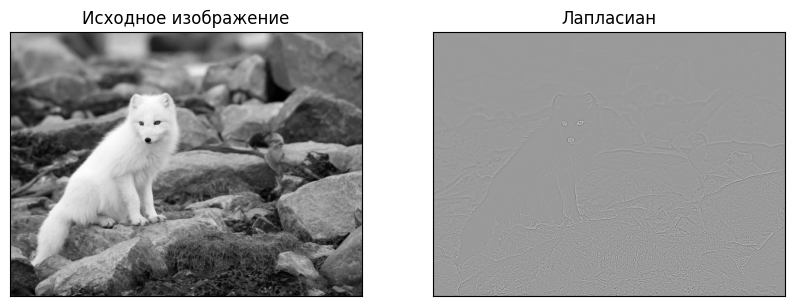

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загрузим изображение в градациях серого
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)

# Вычислим Лапласиан
laplacian = cv2.Laplacian(img, cv2.CV_64F)

# Увеличим размер графиков
plt.figure(figsize=(10, 5))

# Отобразим результаты
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray')
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(1, 2, 2), plt.imshow(laplacian, cmap='gray')
plt.title('Лапласиан'), plt.xticks([]), plt.yticks([])

plt.show()

### 1.3. Алгоритм Кэнни

Алгоритм Кэнни — это популярный метод обнаружения краёв в изображениях, который включает несколько этапов для точного выделения границ.



Давайте разберём каждый шаг подробно:

#### Шаг 1: Преобразование в градации серого и сглаживание

- **Преобразование в градации серого**:
  - Изображение сначала преобразуется в градации серого, если оно цветное. Это упрощает дальнейшую обработку, так как нужно работать только с одним каналом.

- **Сглаживание с помощью фильтра Гаусса**:
  - Применяется фильтр Гаусса для уменьшения шума. Шум может привести к ложным краям, поэтому его необходимо минимизировать. Фильтр Гаусса размывает изображение, сохраняя при этом основные структуры.

#### Шаг 2: Вычисление градиентов

- **Операторы Собеля**:
  - Используются для вычисления производных по X и Y. Это позволяет определить, как быстро изменяется интенсивность изображения в каждом направлении. Результатом являются два изображения градиентов: по горизонтали $G_x$ и по вертикали $G_y$.

#### Шаг 3: Нахождение величины и направления градиента

- **Величина градиента**:
  - Вычисляется как:
  $
  G = \sqrt{G_x^2 + G_y^2}
  $
  - Это значение показывает, насколько резко изменяется интенсивность в каждой точке.

- **Направление градиента**:
  - Определяется как:
    $
    \theta = \arctan\left(\frac{G_y}{G_x}\right)
    $
  - Направление градиента указывает, в каком направлении происходит наибольшее изменение интенсивности.

#### Шаг 4: Подавление немаксимумов (Non-maximum Suppression)

- **Удаление пикселей, которые не являются частью края**:
  - Этот шаг заключается в том, чтобы оставить только те пиксели, которые являются локальными максимумами в направлении градиента. Это помогает сузить края до одной линии пикселей.

#### Шаг 5: Двойная пороговая обработка

- **Применение нижнего и верхнего порогов**:
  - Используются два порога: нижний и верхний. Пиксели с градиентом выше верхнего порога считаются точными краями, а те, что между порогами, — потенциальными краями.

#### Шаг 6: Гистерезисное расширение

- **Объединение слабых краёв с сильными**:
  - Слабые края, которые связаны с сильными краями, также считаются частью границы. Это позволяет избежать разрывов в обнаруженных краях.



### Реализация в OpenCV:

Функция `cv2.Canny` в OpenCV используется для обнаружения краёв на изображении с помощью алгоритма Кэнни. Этот алгоритм является одним из самых популярных методов для выделения границ объектов. Давайте рассмотрим параметры функции и её работу более подробно.



#### Синтаксис функции

```python
cv2.Canny(image, threshold1, threshold2, edges=None, apertureSize=3, L2gradient=False)
```

#### Параметры

1. **`image`**:
   - **Тип**: `numpy.ndarray`
   - **Описание**: Исходное изображение, к которому применяется детектор Кэнни. Обычно это изображение в градациях серого, так как алгоритм работает с одним каналом.

2. **`threshold1`**:
   - **Тип**: `float`
   - **Описание**: Нижний порог для гистерезисного порогового преобразования. Пиксели с градиентом ниже этого значения будут отброшены.

3. **`threshold2`**:
   - **Тип**: `float`
   - **Описание**: Верхний порог для гистерезисного порогового преобразования. Пиксели с градиентом выше этого значения будут считаться точными краями.

4. **`edges`**:
   - **Тип**: `numpy.ndarray` (необязательный)
   - **Описание**: Конечное изображение, в котором будут храниться обнаруженные края. Если не указано, создается автоматически.

5. **`apertureSize`**:
   - **Тип**: `int` (необязательный)
   - **Описание**: Размер апертуры для оператора Собеля, который используется для вычисления градиентов. По умолчанию равен 3. Может быть 3, 5, или 7.

6. **`L2gradient`**:
   - **Тип**: `bool` (необязательный)
   - **Описание**: Флаг, указывающий, использовать ли уравнение L2 для вычисления величины градиента. Если `True`, используется более точная формула$\sqrt{(dI/dx)^2 + (dI/dy)^2}$. Если `False`, используется приближённая формула$|dI/dx| + |dI/dy|$. По умолчанию `False`.

Вот пример, как можно реализовать алгоритм Кэнни в Python с использованием OpenCV:

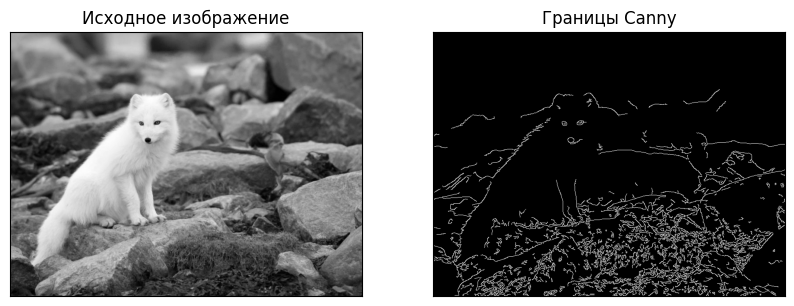

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загрузим изображение в градациях серого
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)

# Применим оператор Canny
edges = cv2.Canny(img, 100, 200)

# Увеличим размер графиков
plt.figure(figsize=(10, 5))

# Отобразим результаты
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray')
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(1, 2, 2), plt.imshow(edges, cmap='gray')
plt.title('Границы Canny'), plt.xticks([]), plt.yticks([])

plt.show()

В этом коде изображение сначала преобразуется в градации серого, затем сглаживается с помощью фильтра Гаусса. После этого применяется функция `cv2.Canny`, которая выполняет все описанные шаги для обнаружения краёв.

Параметры 100 и 200 — это нижний и верхний пороги для гистерезисного порогового преобразования.

## 2. Обнаружение контуров


Обнаружение контуров — это важный процесс в компьютерном зрении, который позволяет выделять и анализировать формы объектов на изображении. Контуры представляют собой линии, соединяющие точки с одинаковой интенсивностью, и могут быть использованы для распознавания объектов, анализа их формы и других задач. Давайте разберём, как это работает, шаг за шагом.

#### **Теория и математическое обоснование**


Контуры — это кривые, которые соединяют все непрерывные точки вдоль границы, имеющие одинаковый цвет или интенсивность. Обнаружение контуров полезно для анализа формы, распознавания объектов и других задач в компьютерном зрении.

#### **Практические шаги по обнаружению контуров**








##### **Шаг 1: Преобразование изображения в градации серого**

- **Почему это важно**:
  - Цветные изображения содержат три канала (RGB), что усложняет обработку. Преобразование в градации серого упрощает задачу, так как остаётся только один канал для анализа.

- **Как это сделать**:
  - Используйте функцию `cv2.cvtColor` для преобразования цветного изображения в градации серого.

##### **Шаг 2: Применение пороговой обработки или оператора Кэнни**

- **Цель**:
  - Получить бинарное изображение, где пиксели либо чёрные, либо белые. Это упрощает задачу обнаружения контуров.

- **Методы**:
  - **Пороговая обработка**: Используйте `cv2.threshold` для преобразования изображения в бинарное, задав пороговое значение.
  - **Оператор Кэнни**: Используйте `cv2.Canny` для обнаружения краёв, что также приводит к бинарному изображению.

##### **Шаг 3: Нахождение контуров**

- **Как это работает**:
  - Функция `cv2.findContours` находит контуры на бинаризованном изображении. Она возвращает список контуров, где каждый контур представлен как массив точек.

- **Что возвращает**:
  - Контуры и иерархию контуров, что может быть полезно для анализа вложенных объектов.

##### **Шаг 4: Отрисовка контуров**

  - Используйте функцию `cv2.drawContours` для отрисовки найденных контуров на изображении.



Функция `cv2.findContours` в OpenCV используется для обнаружения контуров на бинаризованном изображении. Контуры представляют собой линии, соединяющие точки с одинаковой интенсивностью, и могут быть использованы для анализа формы объектов и их распознавания. Давайте рассмотрим параметры функции и её работу более подробно.



#### Синтаксис функции

```python
contours, hierarchy = cv2.findContours(image, mode, method, contours=None, offset=None)
```

#### Параметры

1. **`image`**:
   - **Тип**: `numpy.ndarray`
   - **Описание**: Исходное бинарное изображение, на котором будут обнаруживаться контуры. Обычно это изображение, полученное после пороговой обработки или применения оператора Кэнни. Важно, чтобы изображение было бинарным, так как функция ищет границы между чёрными и белыми областями.

2. **`mode`**:
   - **Тип**: `int`
   - **Описание**: Режим извлечения контуров. Определяет, как будут возвращаться контуры и их иерархия. Возможные значения:
     - `cv2.RETR_EXTERNAL`: Извлекает только внешние контуры.
     - `cv2.RETR_LIST`: Извлекает все контуры без иерархии.
     - `cv2.RETR_CCOMP`: Извлекает все контуры и организует их в двухуровневую иерархию.
     - `cv2.RETR_TREE`: Извлекает все контуры и организует их в полную иерархию вложенности.

3. **`method`**:
   - **Тип**: `int`
   - **Описание**: Метод аппроксимации контуров. Определяет, как будут аппроксимироваться контуры. Возможные значения:
     - `cv2.CHAIN_APPROX_NONE`: Сохраняет все точки контура.
     - `cv2.CHAIN_APPROX_SIMPLE`: Упрощает контур, удаляя избыточные точки и оставляя только ключевые.
     - `cv2.CHAIN_APPROX_TC89_L1` и `cv2.CHAIN_APPROX_TC89_KCOS`: Используют алгоритмы Teh-Chin для аппроксимации.

4. **`contours`**:
   - **Тип**: `list` (необязательный)
   - **Описание**: Список, в который будут записаны найденные контуры. Если не указан, создаётся автоматически.

5. **`offset`**:
   - **Тип**: `tuple` (необязательный)
   - **Описание**: Смещение, которое будет добавлено ко всем точкам контура. Полезно, если вы хотите сдвинуть контуры относительно исходного изображения.

#### Возвращаемые значения

- **`contours`**:
  - Список найденных контуров. Каждый контур представлен как массив точек.

- **`hierarchy`**:
  - Массив, описывающий иерархию контуров. Полезен для анализа вложенных контуров.

**Практическое применение с кодом**

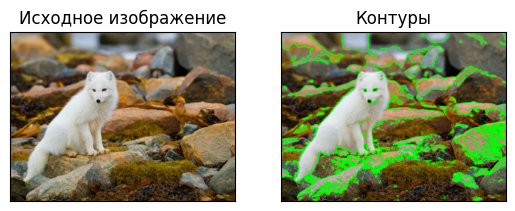

In [ ]:
# Загрузим изображение
img = cv2.imread('image.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Применим пороговую обработку
ret, thresh = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

# Найдем контуры
contours, hierarchy = cv2.findContours(thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

# Скопируем изображение для отрисовки контуров
img_contours = img.copy()

# Нарисуем контуры
cv2.drawContours(img_contours, contours, -1, (0, 255, 0), 2)

# Отобразим результаты
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(1, 2, 2), plt.imshow(cv2.cvtColor(img_contours, cv2.COLOR_BGR2RGB))
plt.title('Контуры'), plt.xticks([]), plt.yticks([])
plt.show()

**Пояснения к параметрам `cv2.findContours()`:**

- `thresh` — бинарное изображение, на котором будут найдены контуры.
- `cv2.RETR_TREE` — режим извлечения контуров. Этот параметр определяет, каким образом будут извлекаться контуры (иерархия контуров).
- `cv2.CHAIN_APPROX_SIMPLE` — метод приближения контуров. Этот параметр определяет, как будут упрощаться контуры для уменьшения количества точек.

## 3. Заключение

Выделение границ и контуров является фундаментальным инструментом в области компьютерного зрения. Операторы Собеля, Лапласа и Кэнни предоставляют различные способы обнаружения краёв, основываясь на различных математических подходах. После выявления краёв можно использовать методы обнаружения контуров для анализа форм и структур объектов на изображении.

## 4. Дополнительные примеры и советы

### 4.1. Настройка параметров оператора Кэнни

Параметры нижнего и верхнего порогов сильно влияют на результат обнаружения краёв. Рекомендуется проводить экспериментальные проверки для каждого конкретного изображения.

In [ ]:
edges = cv2.Canny(img, threshold1=50, threshold2=150)

### 4.2. Использование размытия для улучшения результатов

Перед применением операторов градиента рекомендуется сгладить изображение, чтобы уменьшить влияние шума.

In [ ]:
# Применим размытие
blur = cv2.GaussianBlur(img, (3, 3), 0)

# Далее применяем операторы Собеля или Лапласа на размытом изображении
sobelx = cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=3)

### 4.3. Иерархия контуров

Функция `cv2.findContours()` возвращает также информацию об иерархии контуров. Это может быть полезно для анализа вложенных объектов.

In [ ]:
# Найдем контуры и иерархию
contours, hierarchy = cv2.findContours(thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

# hierarchy имеет форму (1, N, 4), где N - количество контуров
hierarchy

array([[[  1,  -1,  -1,  -1],
        [  2,   0,  -1,  -1],
        [  3,   1,  -1,  -1],
        ...,
        [852,  -1,  -1, 850],
        [853, 851,  -1, 850],
        [ -1, 852,  -1, 850]]], dtype=int32)

Каждый элемент в `hierarchy` содержит четыре значения:

- `hierarchy[0][i][0]` – индекс следующего контура на том же уровне.
- `hierarchy[0][i][1]` – индекс предыдущего контура на том же уровне.
- `hierarchy[0][i][2]` – индекс первого дочернего контура.
- `hierarchy[0][i][3]` – индекс родительского контура.

## 5. Заключение

При правильном использовании операторы градиента и методы обнаружения контуров позволяют значительно упростить задачи анализа изображений, такие как сегментация, распознавание объектов и отслеживание.

**Примечание:** При работе с реальными изображениями важно учитывать их качество, наличие шума и прочие факторы, которые могут влиять на результат обработки. Рекомендуется предварительная обработка изображений, включая коррекцию яркости, контраста и фильтрацию шума.

# Обнаружение границ с использованием различных инструментов

Выделение границ на изображениях является одной из ключевых задач в области обработки изображений и компьютерного зрения. Границы содержат важную информацию о форме и структуре объектов, что способствует распознаванию и анализу изображений.

Далее мы рассмотрим следующие методы обнаружения границ:

1. **Использование фильтров Габора**.
2. **Операторы Прюитта и Робертса**.
3. **Сравнение методов и их применение в различных задачах**.

Каждый раздел будет включать в себя теоретическое обоснование, математическое описание и практические примеры реализации на Python с использованием OpenCV.

---

## 1. Использование фильтров Габора

### Теория и математическое обоснование

**Фильтры Габора** представляют собой линейные фильтры, используемые для анализа текстурных особенностей изображения в различных масштабах и ориентациях. Они эффективно локализуют пространственные частоты в определенных областях изображения.

Двумерный фильтр Габора можно описать с помощью функции:

$
G(x, y; \lambda, \theta, \psi, \sigma, \gamma) = \exp\left( -\frac{x'^2 + \gamma^2 y'^2}{2 \sigma^2} \right) \cos\left( 2\pi \frac{x'}{\lambda} + \psi \right)
$

где:

- $ x' = x \cos\theta + y \sin\theta $
- $ y' = -x \sin\theta + y \cos\theta $

**Параметры фильтра:**

- $ \lambda $ (lambda): длина волны синусоидальной составляющей.
- $ \theta $ (theta): ориентация нормали к полосам Габора.
- $ \psi $ (psi): фазовый сдвиг синусоидальной функции.
- $ \sigma $ (sigma): стандартное отклонение гауссовой оболочки.
- $ \gamma $ (gamma): коэффициент аспектного отношения, определяющий вытянутость гауссианы.

**Особенности фильтров Габора:**

- Позволяют анализировать ориентацию и частоту элементов изображения.
- Могут использоваться для извлечения признаков в задачах распознавания образов.
- Обеспечивают совместную локализацию в пространственном и частотном доменах.

### Практическое применение с примером кода

**Импорт необходимых библиотек:**

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

**Создание фильтра Габора и применение к изображению:**

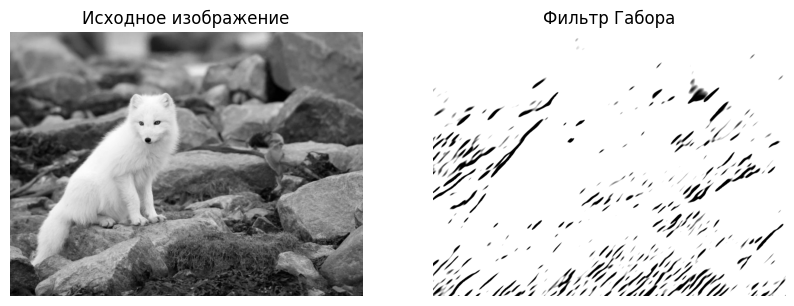

In [ ]:

# Загрузка изображения в градациях серого
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)

# Параметры фильтра Габора
ksize = 31            # Размер ядра
sigma = 4.0           # Стандартное отклонение гауссианы
theta = np.pi / 4     # Ориентация фильтра (в радианах)
lambd = 10.0          # Длина волны
gamma = 0.5           # Коэффициент аспектного отношения
psi = 0               # Фазовый сдвиг
ktype = cv2.CV_32F    # Тип данных ядра

# Создание ядра фильтра Габора
kernel = cv2.getGaborKernel((ksize, ksize), sigma, theta, lambd, gamma, psi, ktype)

# Применение фильтра к изображению
filtered_img = cv2.filter2D(img, cv2.CV_8UC3, kernel)

# Отображение исходного и обработанного изображения
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(filtered_img, cmap='gray')
plt.title('Фильтр Габора')
plt.axis('off')
plt.show()

**Объяснение кода:**

- **cv2.getGaborKernel()** создаёт ядро фильтра Габора с заданными параметрами.
- **cv2.filter2D()** применяет фильтр к изображению.
- Изменяя параметры `theta` и `lambd`, можно выделять особенности в различных направлениях и масштабах.

---

## 2. Операторы Прюитта и Робертса

### 2.1. Оператор Прюитта

#### Теория и математическое обоснование

**Оператор Прюитта** используется для обнаружения градиента интенсивности изображения. Он основан на свёртке изображения с ядрами, которые выделяют горизонтальные и вертикальные изменения интенсивности.

**Ядра оператора Прюитта:**

- **Горизонтальное ядро ($ G_x $):**

$
G_x = \begin{bmatrix}
-1 & 0 & 1 \\
-1 & 0 & 1 \\
-1 & 0 & 1 \\
\end{bmatrix}
$

- **Вертикальное ядро ($ G_y $):**

$
G_y = \begin{bmatrix}
-1 & -1 & -1 \\
 0 &  0 &  0 \\
 1 &  1 &  1 \\
\end{bmatrix}
$

**Вычисление градиента:**

После применения ядер $ G_x $ и $ G_y $, градиент определяется как:

$
G = \sqrt{G_x^2 + G_y^2}
$

#### Практическое применение с примером кода

**Реализация оператора Прюитта в OpenCV:**

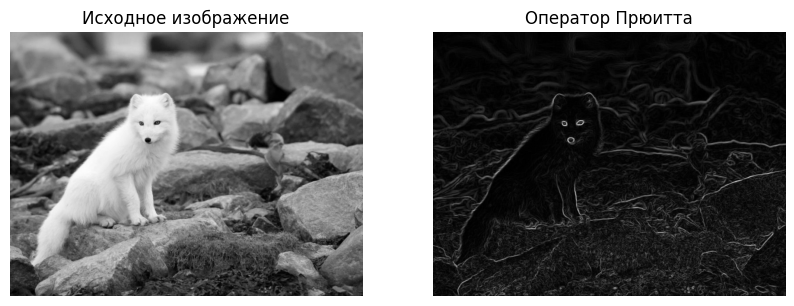

In [ ]:
# Загрузка изображения в градациях серого
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)

# Ядра оператора Прюитта
kernelx = np.array([[ -1, 0, 1],
                    [ -1, 0, 1],
                    [ -1, 0, 1]], dtype=np.float32)

kernely = np.array([[ -1, -1, -1],
                    [  0,  0,  0],
                    [  1,  1,  1]], dtype=np.float32)

# Применение фильтрации
grad_x = cv2.filter2D(img, cv2.CV_32F, kernelx)
grad_y = cv2.filter2D(img, cv2.CV_32F, kernely)

# Вычисление градиента
magnitude = cv2.magnitude(grad_x, grad_y)

# Нормализация для отображения
magnitude = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX)

# Отображение результатов
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(magnitude, cmap='gray')
plt.title('Оператор Прюитта')
plt.axis('off')
plt.show()

---

### 2.2. Оператор Робертса

#### Теория и математическое обоснование

**Оператор Робертса** является одним из самых простых методов для выделения границ. Он основан на вычислении диагональных градиентов с помощью небольших 2x2 ядер.

**Ядра оператора Робертса:**

- **Горизонтальное ядро ($ G_x $):**

$
G_x = \begin{bmatrix}
1 & 0 \\
0 & -1 \\
\end{bmatrix}
$

- **Вертикальное ядро ($ G_y $):**

$
G_y = \begin{bmatrix}
0 & 1 \\
-1 & 0 \\
\end{bmatrix}
$

**Вычисление градиента:**

$
G = \sqrt{G_x^2 + G_y^2}
$

#### Практическое применение с примером кода

**Реализация оператора Робертса в OpenCV:**

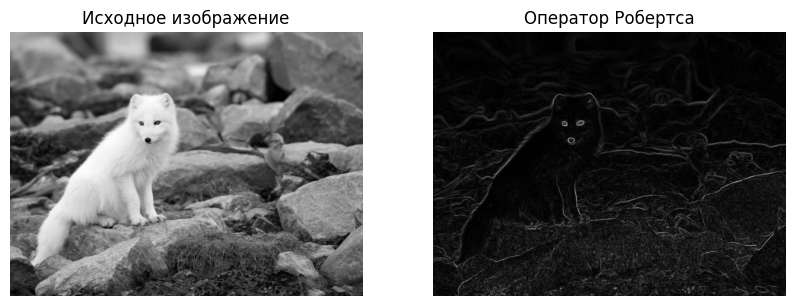

In [ ]:
# Загрузка изображения в градациях серого
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)

# Ядра оператора Робертса
kernelx = np.array([[1, 0],
                    [0, -1]], dtype=np.float32)

kernely = np.array([[0, 1],
                    [-1, 0]], dtype=np.float32)

# Применение фильтрации
grad_x = cv2.filter2D(img, cv2.CV_32F, kernelx)
grad_y = cv2.filter2D(img, cv2.CV_32F, kernely)

# Вычисление градиента
magnitude = cv2.magnitude(grad_x, grad_y)

# Нормализация для отображения
magnitude = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX)

# Отображение результатов
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(magnitude, cmap='gray')
plt.title('Оператор Робертса')
plt.axis('off')
plt.show()

---

## 3. Сравнение методов и их применение в различных задачах

### Сравнение методов

| Критерий             | Фильтры Габора                                            | Оператор Прюитта                         | Оператор Робертса                         |
|----------------------|-----------------------------------------------------------|------------------------------------------|-------------------------------------------|
| **Размер ядра**      | Пользовательский (обычно больше)                          | 3x3                                      | 2x2                                       |
| **Направления**      | Много направлений (настраиваемое)                         | Горизонтальное и вертикальное            | Диагональное                              |
| **Чувствительность** | Чувствителен к ориентации и частоте                       | Чувствителен к вертикальным и горизонтальным градиентам | Чувствителен к диагональным градиентам |
| **Выраженность шума**| Менее чувствителен к шуму (благодаря гауссовой оболочке)  | Умеренно чувствителен                    | Более чувствителен (из-за маленького ядра)|
| **Выделение текстур**| Хорошо подходит для анализа текстур                       | Не предназначен для текстур              | Не предназначен для текстур               |
| **Сложность**        | Более сложный и ресурсоёмкий                              | Простой                                  | Очень простой                             |

### Применение в различных задачах

- **Фильтры Габора:**
  - **Применение:** Распознавание текстур, биометрическая идентификация (отпечатки пальцев, радужка глаза), выделение определенных частотных компонентов.
  - **Преимущества:** Способны выделять специфические пространственные частоты и ориентации.
  - **Недостатки:** Высокая вычислительная сложность, требуются настройки параметров.

- **Оператор Прюитта:**
  - **Применение:** Общие задачи обнаружения краев, где требуется баланс между точностью и вычислительной сложностью.
  - **Преимущества:** Простота реализации, более устойчив к шуму по сравнению с оператором Робертса.
  - **Недостатки:** Может пропустить диагональные границы.

- **Оператор Робертса:**
  - **Применение:** Простые и быстрые приложения, где важна скорость обработки.
  - **Преимущества:** Очень быстрое вычисление из-за малого размера ядра.
  - **Недостатки:** Высокая чувствительность к шуму, менее точен в обнаружении границ.

### Практическое сравнение на одном изображении

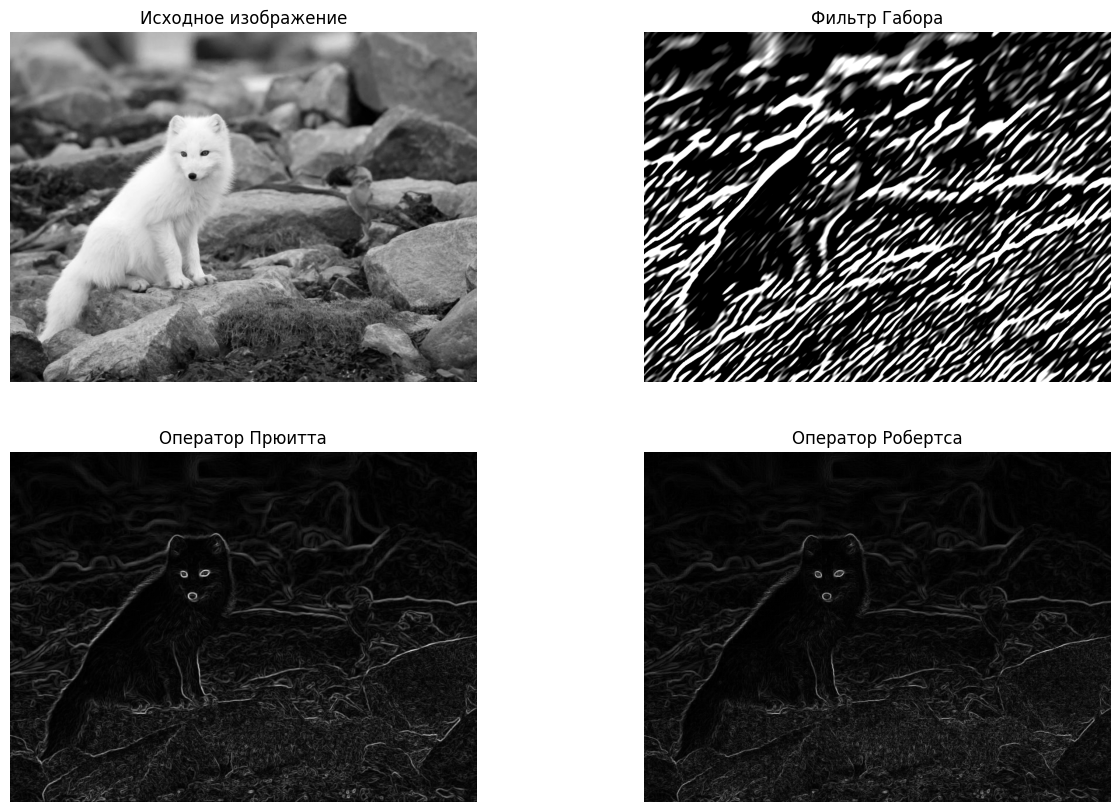

In [ ]:
# Загрузка изображения в градациях серого
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)

# Применение фильтра Габора
ksize = 31
sigma = 4.0
theta = np.pi / 4
lambd = 10.0
gamma = 0.5
gabor_kernel = cv2.getGaborKernel((ksize, ksize), sigma, theta, lambd, gamma)
gabor_filtered = cv2.filter2D(img, cv2.CV_8UC3, gabor_kernel)

# Оператор Прюитта
kernelx_p = np.array([[ -1, 0, 1],
                      [ -1, 0, 1],
                      [ -1, 0, 1]], dtype=np.float32)
kernely_p = np.array([[ -1, -1, -1],
                      [  0,  0,  0],
                      [  1,  1,  1]], dtype=np.float32)
grad_x_p = cv2.filter2D(img, cv2.CV_32F, kernelx_p)
grad_y_p = cv2.filter2D(img, cv2.CV_32F, kernely_p)
magnitude_p = cv2.magnitude(grad_x_p, grad_y_p)
magnitude_p = cv2.normalize(magnitude_p, None, 0, 255, cv2.NORM_MINMAX)

# Оператор Робертса
kernelx_r = np.array([[1, 0],
                      [0, -1]], dtype=np.float32)
kernely_r = np.array([[0, 1],
                      [-1, 0]], dtype=np.float32)
grad_x_r = cv2.filter2D(img, cv2.CV_32F, kernelx_r)
grad_y_r = cv2.filter2D(img, cv2.CV_32F, kernely_r)
magnitude_r = cv2.magnitude(grad_x_r, grad_y_r)
magnitude_r = cv2.normalize(magnitude_r, None, 0, 255, cv2.NORM_MINMAX)

# Отображение результатов
plt.figure(figsize=(15,10))

plt.subplot(2,2,1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(2,2,2)
plt.imshow(gabor_filtered, cmap='gray')
plt.title('Фильтр Габора')
plt.axis('off')

plt.subplot(2,2,3)
plt.imshow(magnitude_p, cmap='gray')
plt.title('Оператор Прюитта')
plt.axis('off')

plt.subplot(2,2,4)
plt.imshow(magnitude_r, cmap='gray')
plt.title('Оператор Робертса')
plt.axis('off')

plt.show()

**Анализ результатов:**

- **Фильтр Габора** выделяет текстуры и границы в определенной ориентации, заданной параметром `theta`.
- **Оператор Прюитта** хорошо выявляет горизонтальные и вертикальные границы.
- **Оператор Робертса** быстро обрабатывает изображение, но показывает менее отчетливые границы и более чувствителен к шуму.

---

## Выводы

- **Фильтры Габора** позволяют выделять текстурные особенности и частотные компоненты изображения. Они полезны в задачах распознавания образов и анализа текстур, но требуют настройки параметров и обладают высокой вычислительной сложностью.

- **Операторы Прюитта и Робертса** являются базовыми методами для обнаружения краев, основанными на вычислении градиентов интенсивности. Они просты в реализации и имеют низкую вычислительную сложность, но отличаются по чувствительности к шуму и способности выявлять границы в различных направлениях.

**Выбор метода зависит от конкретных требований задачи**:

- Если важна скорость обработки и допустимо снижение точности, можно использовать **оператор Робертса**.
- Для более точного выделения горизонтальных и вертикальных границ подходит **оператор Прюитта**.
- Если необходимо анализировать текстурные особенности и пространственные частоты, предпочтительно использовать **фильтры Габора**.

---

## Дополнительные рекомендации

- **Предобработка изображений**: перед применением операторов краевых детекторов рекомендуется выполнять сглаживание изображения (например, с помощью гауссова размытия) для снижения шума.

In [ ]:
# Сглаживание изображения
img_blur = cv2.GaussianBlur(img, (3, 3), 0)

- **Настройка параметров**: экспериментируйте с параметрами фильтров, особенно с фильтром Габора, чтобы добиться наилучших результатов для вашей задачи.

- **Комбинирование методов**: для улучшения качества выделения границ можно комбинировать результаты различных операторов.

In [ ]:
# Комбинирование результатов операторов Прюитта и Робертса
combined = cv2.addWeighted(magnitude_p, 0.5, magnitude_r, 0.5, 0)

- **Пороговая обработка**: после применения операторов можно выполнить пороговую обработку для получения бинарного изображения границ.

In [ ]:
# Применение пороговой обработки
_, thresh = cv2.threshold(magnitude_p, 50, 255, cv2.THRESH_BINARY)

---

**В заключение**, понимание теоретических основ и практических аспектов различных методов обнаружения границ позволяет выбирать наиболее подходящие инструменты для решения конкретных задач в области обработки изображений и компьютерного зрения.

# Преобразование Хафа

**Преобразование Хафа** является одним из фундаментальных методов в компьютерном зрении для обнаружения простых геометрических форм на изображениях, таких как прямые, окружности и другие кривые, которые могут быть описаны параметрическими уравнениями. Основная идея преобразования Хафа заключается в преобразовании области поиска из пространственного домена (изображения) в параметрический домен (пространство параметров) с целью выявления объектов заданной формы.

Далее мы подробно рассмотрим теорию и математическое обоснование преобразования Хафа для обнаружения прямых и кругов, а также практическое применение этих методов с помощью функций OpenCV: `cv2.HoughLines()` и `cv2.HoughCircles()`. Примеры кода на Python помогут лучше понять применение этих методов на практике.

---

## 1. Теория преобразования Хафа

### 1.1. Обнаружение прямых

#### Математическое обоснование

**Уравнение прямой в декартовых координатах:**

В двумерном пространстве прямая может быть описана с помощью уравнения:

$
y = kx + b
$

где $ k $ — угловой коэффициент (наклон), $ b $ — смещение (пересечение с осью Y).

Однако такое представление неудобно для вертикальных прямых, где $ k $ стремится к бесконечности. Поэтому для преобразования Хафа используется **нормальное или полярное представление прямой**:

$
\rho = x \cos\theta + y \sin\theta
$

где:

- $ \rho $ — расстояние от начала координат до прямой,
- $ \theta $ — угол между осью X и перпендикуляром к прямой.

**Преобразование изображения в параметрическое пространство:**

- Каждая точка $ (x, y) $ на границе изображения может соответствовать множеству прямых, проходящих через эту точку.
- В параметрическом пространстве $ (\rho, \theta) $ каждая точка изображения преобразуется в синусоиду.
- Пересечение синусоид разных точек указывает на параметры прямой, которая проходит через эти точки.

**Алгоритм обнаружения прямых:**

1. **Предобработка изображения**:

   - Преобразование изображения в градации серого.
   - Применение алгоритма обнаружения границ (например, метод Кэнни).

2. **Построение аккумуляторного массива**:

   - Создаётся двумерный массив (аккумулятор), где оси представляют диапазоны $ \rho $ и $ \theta $.
   - Для каждой точки границы $ (x, y) $ вычисляются значения $ \rho $ при различных $ \theta $ и инкрементируется соответствующая ячейка в аккумуляторе.

3. **Поиск максимумов в аккумуляторном массиве**:

   - Ячейки с наибольшими значениями соответствуют параметрам прямых, наиболее вероятно присутствующих на изображении.

### **Практическое применение с использованием OpenCV**

#### **Функция cv2.HoughLines()**

**Синтаксис:**

In [ ]:
lines = cv2.HoughLines(image, rho, theta, threshold, lines=None, srn=0, stn=0, min_theta=0, max_theta=np.pi)

- **image**: 8-битное изображение однородного цвета, обычно результат применения оператора Кэнни.
- **rho**: разрешение в радиусе (обычно 1 пиксель).
- **theta**: разрешение в угле в радианах (обычно np.pi/180).
- **threshold**: количество пересечений, необходимое для обнаружения линии.
- **lines**: выходной массив для хранения найденных линий.
- **srn** и **stn**: параметры для многоуровневого преобразования Хафа (обычно не используются).
- **min_theta** и **max_theta**: минимальный и максимальный угол для поиска линий.

**Шаг 1: Импорт библиотек и загрузка изображения**

In [ ]:
!curl -o road.jpg https://www.downloadclipart.net/large/5841-house-27-design.png

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 16951  100 16951    0     0   8578      0  0:00:01  0:00:01 --:--:--  8578


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загрузка изображения
img = cv2.imread('/content/road.jpg')

**Шаг 2: Предобработка изображения**

In [ ]:
# Преобразование в градации серого
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Применение размытия для уменьшения шума
gray = cv2.GaussianBlur(gray, (5, 5), 0)

# Выделение границ с помощью метода Кэнни
edges = cv2.Canny(gray, 50, 150, apertureSize=3)

**Шаг 3: Применение преобразования Хафа для обнаружения прямых**

In [ ]:
# Параметры для функции HoughLines
rho_resolution = 1            # Шаг изменения rho в пикселях
theta_resolution = np.pi / 180  # Шаг изменения theta в радианах
threshold = 75              # Минимальное число пересечений, необходимых для обнаружения линии

# Обнаружение прямых
lines = cv2.HoughLines(edges, rho_resolution, theta_resolution, threshold)

**Шаг 4: Отображение найденных прямых**

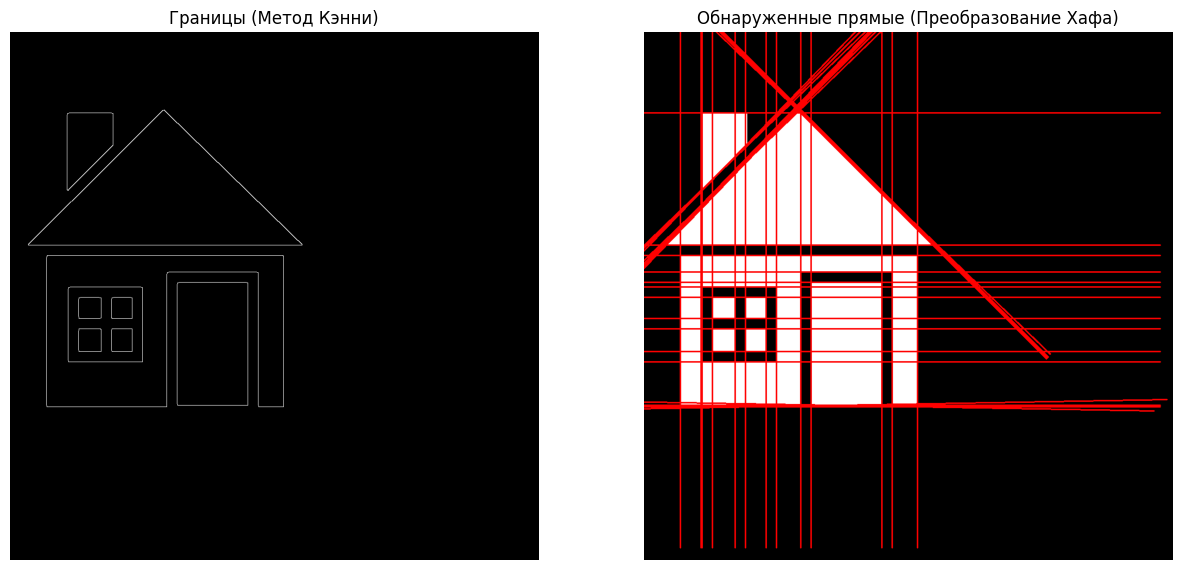

In [ ]:
# Создание копии исходного изображения для отображения результатов
img_lines = img.copy()

# Проверка, найдены ли линии
if lines is not None:
    for line in lines:
        rho, theta = line[0]
        # Преобразование параметров обратно в координаты точек
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        # Определение координат точки на прямой
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * a)
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * a)
        # Рисование линии на изображении
        cv2.line(img_lines, (x1, y1), (x2, y2), (0, 0, 255), 2)
else:
    print("Прямые не найдены")

# Отображение результатов
plt.figure(figsize=(15, 10))
plt.subplot(1, 2, 1)
plt.title('Границы (Метод Кэнни)')
plt.imshow(edges, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Обнаруженные прямые (Преобразование Хафа)')
plt.imshow(cv2.cvtColor(img_lines, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

**Пояснение коду:**

- **`cv2.HoughLines()`** возвращает массив линий, каждая из которых описана параметрами $ (\rho, \theta) $.
- Линии рисуются на изображении с помощью функции **`cv2.line()`**, для которой координаты точек вычисляются из параметров $ \rho $ и $ \theta $.
- Умножение на 1000 используется для рисования длинных линий, которые простираются за пределы изображения.

---

### **Функция cv2.HoughLinesP()**

**cv2.HoughLinesP()** — вероятностное преобразование Хафа, которое представляет линии в виде отрезков.

**Синтаксис:**

In [ ]:
lines = cv2.HoughLinesP(image, rho, theta, threshold, minLineLength=None, maxLineGap=None)

- **minLineLength**: минимальная длина линии. Линии меньше этой длины будут игнорироваться.
- **maxLineGap**: максимальный разрыв между сегментами, которые будут считаться одной линией.

**Пример использования cv2.HoughLinesP():**

In [ ]:
lines = cv2.HoughLinesP(edges, rho_resolution, theta_resolution, threshold)

**Отображение линий:**

Найдено линий: 32


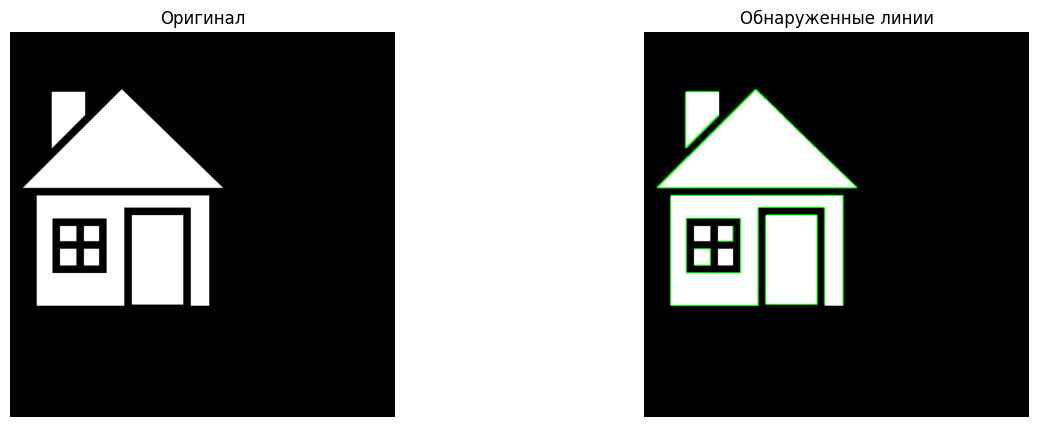

In [ ]:
# Создаем копию изображения
img_linesP = img.copy()

# Проверяем и рисуем линии
if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]
        cv2.line(img_linesP, (x1, y1), (x2, y2), (0, 255, 0), 2)

    print(f"Найдено линий: {len(lines)}")  # Добавим отладочную информацию
else:
    print("Линии не найдены")

# Отображение результата
plt.figure(figsize=(15, 5))
plt.subplot(121)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Оригинал')
plt.axis('off')

plt.subplot(122)
plt.imshow(cv2.cvtColor(img_linesP, cv2.COLOR_BGR2RGB))
plt.title('Обнаруженные линии')
plt.axis('off')
plt.show()

### 1.2. Обнаружение кругов

#### Математическое обоснование

**Уравнение окружности в декартовых координатах:**

$
(x - a)^2 + (y - b)^2 = r^2
$

где:

- $ (a, b) $ — координаты центра окружности,
- $ r $ — радиус окружности.

**Преобразование Хафа для окружностей:**

- Чтобы обнаружить круги на изображении, необходимо трёхмерное параметрическое пространство $ (a, b, r) $, что увеличивает вычислительную сложность.
- Для оптимизации используется метод **Хафа с накоплением градиента (Gradient Hough Transform)** или **Метод Хафа для кругов с использованием градиентной информации**.

**Алгоритм обнаружения окружностей:**

1. **Предобработка изображения**:

   - Преобразование в градации серого.
   - Размытие для снижения шума.

2. **Обнаружение краев с помощью метода Кэнни**.

3. **Применение преобразования Хафа для кругов**:

   - Для каждой точки границы используется окружность со всеми возможными радиусами и центрами.
   - Накопление в трёхмерном аккумуляторе $ (a, b, r) $.
   - Поиск пиков в аккумуляторном пространстве, соответствующих окружностям на изображении.

#### **Практическое применение с использованием OpenCV**

### **Функция cv2.HoughCircles()**

**Синтаксис:**

In [ ]:
circles = cv2.HoughCircles(image, method, dp, minDist, param1, param2, minRadius, maxRadius)

- **image**: 8-битное, одноканальное, размытое изображение.
- **method**: метод обнаружения (только **cv2.HOUGH_GRADIENT** доступен в OpenCV).
- **dp**: отношение разрешения аккумуляторного массива к разрешению изображения.
- **minDist**: минимальное расстояние между центрами обнаруженных окружностей.
- **param1**: параметр метода Кэнни (порог).
- **param2**: порог для центра обнаружения кругов в аккумуляторном пространстве. Чем меньше значение, тем больше ложных кругов будет обнаружено.
- **minRadius** и **maxRadius**: минимальный и максимальный радиусы кругов для обнаружения.

---

In [ ]:
!curl -o coins.jpg https://cdn.monetnik.ru/storage/market-lot/76/49/115676/348662_mainViewLot_2x.jpg

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  104k  100  104k    0     0  69677      0  0:00:01  0:00:01 --:--:-- 69716


**Шаг 1: Импорт библиотек и загрузка изображения**

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загрузка изображения
img = cv2.imread('coins.jpg')  # Замените 'coins.jpg' на ваш файл изображения

**Шаг 2: Предобработка изображения**

In [ ]:
# Преобразование в градации серого
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Размытие изображения для уменьшения шума
gray_blurred = cv2.medianBlur(gray, 5)

**Шаг 3: Применение преобразования Хафа для обнаружения кругов**

In [ ]:
# Параметры для функции HoughCircles
dp = 1.2                # Параметр разрешения аккумуляторного массива
minDist = 100            # Минимальное расстояние между центрами обнаруженных окружностей
param1 = 50             # Порог для метода Кэнни
param2 = 150            # Порог для функции HoughCircles (чем меньше, тем больше ложных кругов)
minRadius = 50         # Минимальный радиус круга
maxRadius = 250          # Максимальный радиус круга

# Обнаружение кругов
circles = cv2.HoughCircles(gray_blurred, cv2.HOUGH_GRADIENT, dp, minDist,
                           param1=param1, param2=param2,
                           minRadius=minRadius, maxRadius=maxRadius)

**Шаг 4: Отображение найденных кругов**

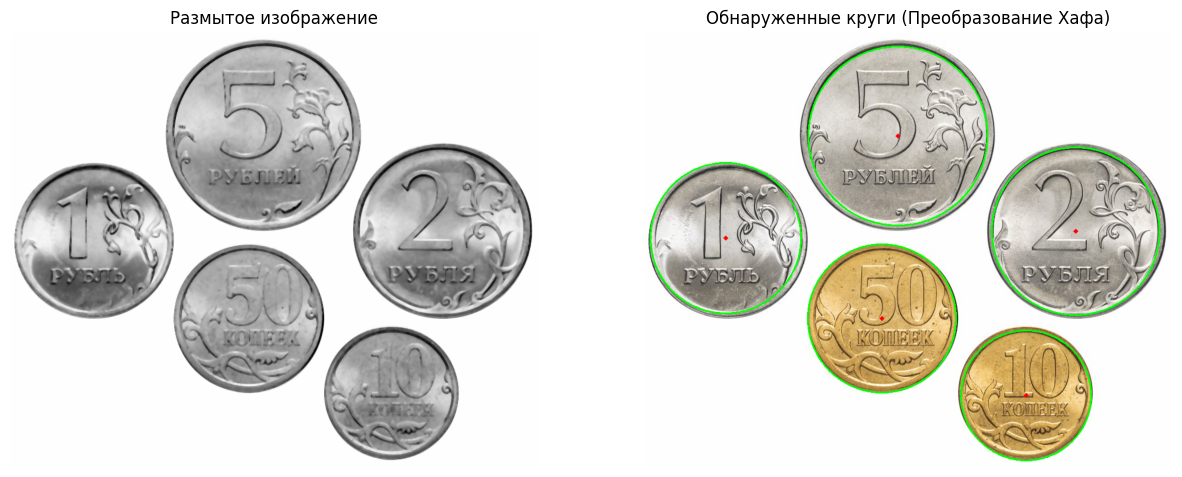

In [ ]:
# Создание копии изображения для отображения результатов
img_circles = img.copy()

# Проверка, найдены ли круги
if circles is not None:
    # Округление координат центров и радиусов до целых чисел
    circles = np.uint16(np.around(circles))
    for circle in circles[0, :]:
        center = (circle[0], circle[1])  # Координаты центра
        radius = circle[2]              # Радиус
        # Рисование контура круга
        cv2.circle(img_circles, center, radius, (0, 255, 0), 2)
        # Рисование центра круга
        cv2.circle(img_circles, center, 2, (0, 0, 255), 3)
else:
    print("Круги не найдены")

# Отображение результатов
plt.figure(figsize=(15, 10))
plt.subplot(1, 2, 1)
plt.title('Размытое изображение')
plt.imshow(gray_blurred, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Обнаруженные круги (Преобразование Хафа)')
plt.imshow(cv2.cvtColor(img_circles, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

**Пояснение коду:**

- **`cv2.HoughCircles()`** обнаруживает окружности на изображении с использованием метода преобразования Хафа.
- Параметр **`cv2.HOUGH_GRADIENT`** указывает, что используется метод градиентного преобразования Хафа.
- Параметры **`dp`**, **`minDist`**, **`param1`**, **`param2`**, **`minRadius`** и **`maxRadius`** позволяют настроить алгоритм для лучшего обнаружения кругов.

---

## 3. Практические рекомендации

### 3.1. Предобработка изображений

- **Размытие изображения** перед обнаружением кругов помогает снизить шум и улучшить результаты.
- **Обнаружение краев** с помощью метода Кэнни улучшает результаты обнаружения прямых.

### 3.2. Настройка параметров

- **Параметры функции** имеют значительное влияние на результаты. Рекомендуется экспериментировать с параметрами таких функций, как `threshold` в `cv2.HoughLines()` и `param1`, `param2` в `cv2.HoughCircles()`.

### 3.3. Использование вероятностного преобразования Хафа

- **cv2.HoughLinesP()** более эффективна для реальных приложений, так как возвращает конечные отрезки линий и имеет меньше ложных обнаружений.

### 3.4. Обработка результатов

- **Отсев ложных объектов**: После обнаружения геометрических фигур можно применять дополнительные критерии (например, размеры, положение), чтобы отсеять ложные положительные результаты.

---

## 4. Заключение

Преобразование Хафа является эффективным инструментом для обнаружения геометрических фигур на изображениях. Оно эффективно справляется с задачами обнаружения прямых и кругов даже на изображениях с шумом или частичными гранями.

Используя функции OpenCV, такие как `cv2.HoughLines()`, `cv2.HoughLinesP()` и `cv2.HoughCircles()`, можно легко применить преобразование Хафа в своих приложениях.

**Важно понимать математику, лежащую в основе этих методов**, чтобы эффективно настраивать параметры функций и обрабатывать результаты.

---

**Примечание:** При работе с реальными изображениями качество предобработки и правильный выбор параметров имеют решающее значение для успешного обнаружения геометрических фигур.

# Геометрические преобразования и перспективная трансформация

Геометрические преобразования изображений являются фундаментальными операциями в обработке изображений и компьютерном зрении. Они позволяют изменять положение, размер, ориентацию и форму объектов на изображении. Далее мы рассмотрим теорию и математическое обоснование следующих преобразований:

1. **Трансформации изображений**: перенос (translation), масштабирование (scaling), поворот (rotation), аффинные преобразования.
2. **Перспективная трансформация**.

Также мы рассмотрим практическое применение этих преобразований с использованием методов OpenCV:

- `cv2.getRotationMatrix2D()`
- `cv2.warpAffine()`
- `cv2.getPerspectiveTransform()`
- `cv2.warpPerspective()`

---

## 1. Трансформации изображений

### 1.1. Перенос (Translation)

**Теория и математическое обоснование**

Перенос изображения заключается в смещении всех его точек на заданное расстояние вдоль осей координат.

Математически, это описывается следующей матрицей преобразования:

$
T = \begin{bmatrix}
1 & 0 & t_x \\
0 & 1 & t_y \\
\end{bmatrix}
$

где $ t_x $ и $ t_y $ — смещения по осям X и Y соответственно.

**Применение**

Чтобы выполнить перенос изображения, необходимо создать матрицу преобразования и использовать функцию `cv2.warpAffine()`.

**Пример кода**

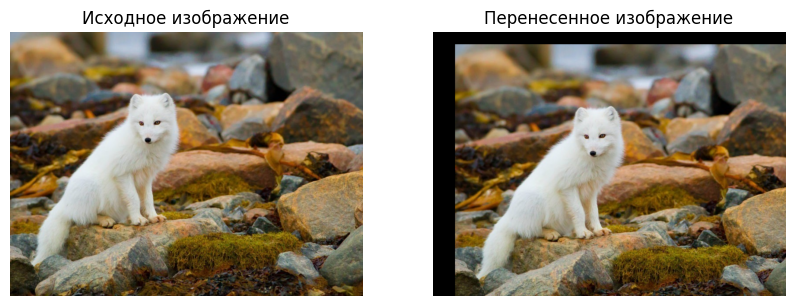

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загрузка изображения
img = cv2.imread('image.jpg')

# Конвертация изображения из BGR в RGB для корректного отображения в matplotlib
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Определение параметров переноса
tx = 50  # Смещение по X
ty = 30  # Смещение по Y

# Создание матрицы переноса
M = np.float32([[1, 0, tx],
                [0, 1, ty]])

# Применение переноса
shifted = cv2.warpAffine(img, M, (img.shape[1], img.shape[0]))

# Отображение результатов рядом по горизонтали
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(shifted)
plt.title('Перенесенное изображение')
plt.axis('off')

plt.show()

---

### 1.2. Масштабирование (Scaling)

**Теория и математическое обоснование**

Масштабирование изменяет размеры изображения по осям X и Y.

Матричное представление масштабирования:

$
S = \begin{bmatrix}
s_x & 0 & 0 \\
0 & s_y & 0 \\
\end{bmatrix}
$

где $ s_x $ и $ s_y $ — коэффициенты масштабирования по осям X и Y соответственно.

**Применение**

Масштабирование можно выполнить с помощью функции `cv2.resize()` или через матрицу преобразования с использованием `cv2.warpAffine()`.

**Пример кода с использованием cv2.resize()**

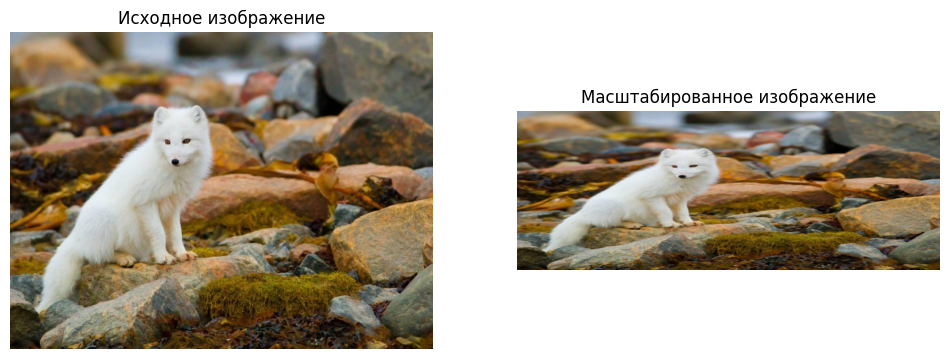

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загрузка изображения
img = cv2.imread('image.jpg')

# Конвертация изображения из BGR в RGB для корректного отображения в matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Коэффициенты масштабирования
sx = 1.5  # Увеличение по X в 1.5 раза
sy = 0.75  # Уменьшение по Y до 75%

# Применение масштабирования
resized = cv2.resize(img_rgb, None, fx=sx, fy=sy, interpolation=cv2.INTER_LINEAR)

# Отображение результатов рядом по горизонтали
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(resized)
plt.title('Масштабированное изображение')
plt.axis('off')

plt.show()

**Пример кода с использованием матрицы масштабирования**

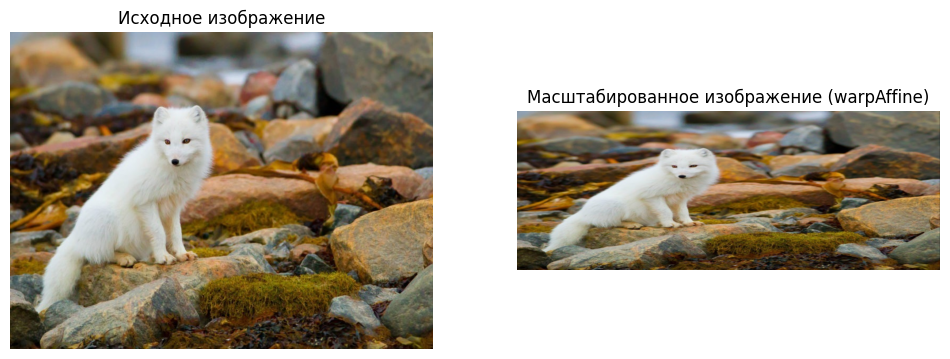

In [ ]:
# Создание матрицы масштабирования
M = np.float32([[sx, 0, 0],
                [0, sy, 0]])

# Применение масштабирования с помощью cv2.warpAffine
scaled = cv2.warpAffine(img_rgb, M, (int(img.shape[1] * sx), int(img.shape[0] * sy)))

# Отображение результатов рядом по горизонтали
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(scaled)
plt.title('Масштабированное изображение (warpAffine)')
plt.axis('off')

plt.show()

---

### 1.3. Поворот (Rotation)

**Теория и математическое обоснование**



Матрица поворота используется для преобразования изображения путем поворота его на заданный угол вокруг определенной точки, обычно центра изображения. Функция `cv2.getRotationMatrix2D` из OpenCV вычисляет аффинную матрицу преобразования для поворота на указанный угол и масштабирования.

Матрица поворота `M` имеет следующий вид:

$
M = \begin{bmatrix}
\alpha & \beta & (1 - \alpha) \cdot center_x - \beta \cdot center_y \\
- \beta & \alpha & \beta \cdot center_x + (1 - \alpha) \cdot center_y
\end{bmatrix}
$

где:

- $ \alpha = scale \cdot \cos(\theta) $
- $ \beta = scale \cdot \sin(\theta) $
- `scale` — коэффициент масштабирования.
- $ \theta $ — угол поворота в радианах.
- `(center_x, center_y)` — координаты центра поворота.

Функция `cv2.warpAffine` применяет эту матрицу к исходному изображению, выполняя его поворот и масштабирование.

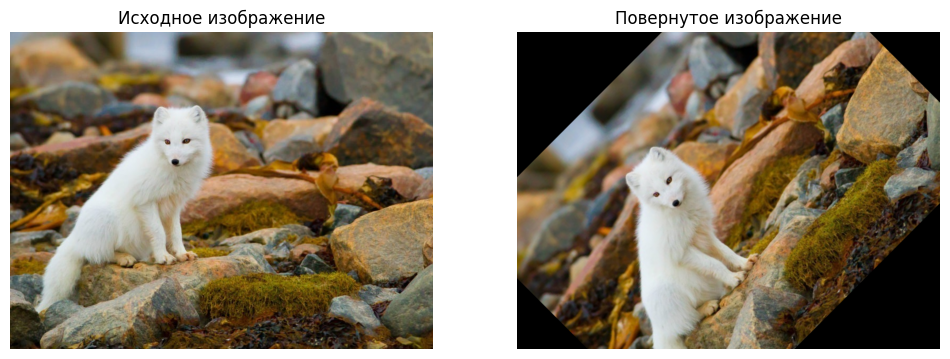

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загрузка изображения
img = cv2.imread('image.jpg')

# Конвертация изображения из BGR в RGB для корректного отображения в matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Задаем угол поворота и масштаб
angle = 45  # Угол в градусах
scale = 1.0  # Масштаб

# Определяем центр изображения
(h, w) = img.shape[:2]
center = (w // 2, h // 2)

# Получаем матрицу поворота
M = cv2.getRotationMatrix2D(center, angle, scale)

# Выполняем поворот
rotated = cv2.warpAffine(img_rgb, M, (w, h))

# Отображение результатов рядом по горизонтали
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(rotated)
plt.title('Повернутое изображение')
plt.axis('off')

plt.show()

---

### 1.4. Аффинные преобразования (Affine Transformations)

**Теория и математическое обоснование**

Аффинное преобразование — линейное преобразование, сохраняющее прямые и параллельные линии. Оно включает в себя комбинацию переноса, масштабирования, поворота и сдвига.

Общая форма матрицы аффинного преобразования:

$
A = \begin{bmatrix}
a_{11} & a_{12} & b_1 \\
a_{21} & a_{22} & b_2 \\
\end{bmatrix}
$

**Математически:**

Для преобразования точки $ (x, y) $ в $ (x', y') $:

$
\begin{cases}
x' = a_{11} x + a_{12} y + b_1 \\
y' = a_{21} x + a_{22} y + b_2 \\
\end{cases}
$

**Определение аффинного преобразования по трем точкам**

Чтобы задать аффинное преобразование, достаточно указать соответствие трех точек до и после преобразования.

**Применение**

OpenCV функция `cv2.warpAffine()` используется для применения аффинного преобразования. Матрица преобразования может быть получена с помощью `cv2.getAffineTransform()`.

**Пример кода**

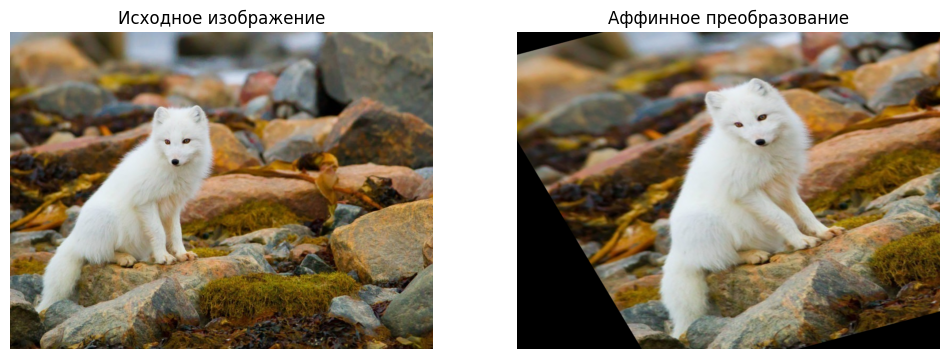

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загрузка изображения
img = cv2.imread('image.jpg')

# Конвертация изображения из BGR в RGB для корректного отображения в matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Исходные точки
pts1 = np.float32([[50, 50],
                   [200, 50],
                   [50, 200]])

# Точки после преобразования
pts2 = np.float32([[10, 100],
                   [200, 50],
                   [100, 250]])

# Получение матрицы аффинного преобразования
M = cv2.getAffineTransform(pts1, pts2)

# Применение аффинного преобразования
affined = cv2.warpAffine(img_rgb, M, (img.shape[1], img.shape[0]))

# Отображение результатов рядом по горизонтали
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(affined)
plt.title('Аффинное преобразование')
plt.axis('off')

plt.show()

---

## 2. Перспективная трансформация

### 2.1. Теория и математическое обоснование

**Перспективная трансформация** позволяет отображать изображение в соответствии с изменением точки зрения. Она используется для преобразования изображения так, чтобы выровнять перспективу, исправить искажения или изменить угол обзора.

Математически, перспективная трансформация описывается следующей матрицей 3x3:

$
P = \begin{bmatrix}
p_{11} & p_{12} & p_{13} \\
p_{21} & p_{22} & p_{23} \\
p_{31} & p_{32} & p_{33} \\
\end{bmatrix}
$

Перспективная трансформация переводит точки $ (x, y) $ в $ (x', y') $ согласно:

$
\begin{cases}
x' = \dfrac{p_{11} x + p_{12} y + p_{13}}{p_{31} x + p_{32} y + p_{33}} \\
y' = \dfrac{p_{21} x + p_{22} y + p_{23}}{p_{31} x + p_{32} y + p_{33}} \\
\end{cases}
$

Для определения перспективной трансформации необходимо задать соответствие четырех точек на исходном и преобразованном изображениях.

### 2.2. Применение

OpenCV предоставляет функции `cv2.getPerspectiveTransform()` для получения матрицы перспективной трансформации и `cv2.warpPerspective()` для применения этой трансформации.

**Пример кода**

In [ ]:
!curl -o sudoku.jpg https://i2.wp.com/jamescrosswordpuzzles.com/wp-content/uploads/2022/06/free-online-sudoku-printable-trackid-sp-006-sudoku-printable.png

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 50225  100 50225    0     0   161k      0 --:--:-- --:--:-- --:--:--  161k


(1575, 1525, 3)


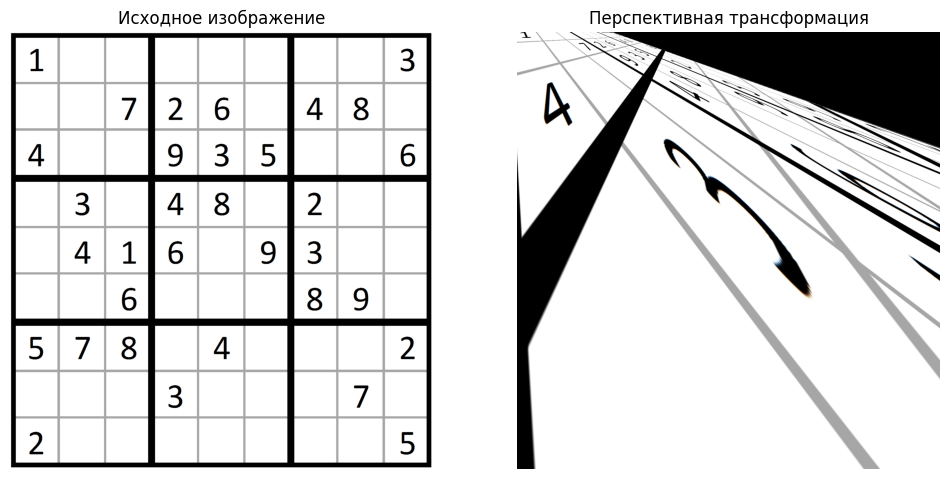

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загрузка изображения
img = cv2.imread('sudoku.jpg')
print(img.shape)

# Конвертация изображения из BGR в RGB для корректного отображения в matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Указание четырех точек на исходном изображении
pts1 = np.float32([[56, 65],
                   [368, 52],
                   [28, 387],
                   [389, 390]])

# Указание точек, куда будут перемещены эти точки
width, height = img.shape[1], img.shape[0]
pts2 = np.float32([[0, 0],
                   [150, 0],
                   [0, 200],
                   [300, 100]])

# Получение матрицы перспективной трансформации
M = cv2.getPerspectiveTransform(pts1, pts2)

# Применение перспективной трансформации
warped = cv2.warpPerspective(img_rgb, M, (width, height))

# Отображение результатов рядом по горизонтали
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(warped)
plt.title('Перспективная трансформация')
plt.axis('off')

plt.show()

**Пояснения к примеру:**

- **Исходные точки $pts1$**: координаты четырех углов объекта на исходном изображении (например, углы документа или таблицы).
- **Новые точки $pts2$**: координаты точек на преобразованном изображении, куда должны соответствовать исходные точки.
- **Размер выходного изображения**: определяется в соответствии с расположением новых точек.

---